# Machine Learning: Exercise session 07

In this exercise session we will focus on tree bagging and random forests for the practical parts.

The theoretical exercise is about the properties of bootstrap. We will derive the probability that a given observation is part of a bootstrap sample.

## 0. Data import and Cleaning

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, train_test_split, GridSearchCV

Import the "Heart" dataset, containing demographic and medical informations about a list of patients. Drop `NA` values, convert the categorical variables into the desired pandas type: "category", and perform any other necessary data cleaning.

In [2]:
data = pd.read_csv('/Users/helianferraris/Desktop/Machine Learning/Exercise_07/Heart_ISL.csv', index_col=0)

data = data.dropna() # removes rows that contain NA

data['ChestPain'] = data['ChestPain'].astype('category')
#data['ChestPain'].dtype
data['Thal'] = data['Thal'].astype('category')
data['AHD'] = data['AHD'].astype('category')

data

# or categorical_columns = ['AHD','ChestPain','Thal']
# data = data.astype({col: 'category' for col in categorical_columns})

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,asymptomatic,140,241,0,0,123,1,0.2,2,0.0,reversable,Yes
299,45,1,typical,110,264,0,0,132,0,1.2,2,0.0,reversable,Yes
300,68,1,asymptomatic,144,193,1,0,141,0,3.4,2,2.0,reversable,Yes
301,57,1,asymptomatic,130,131,0,0,115,1,1.2,2,1.0,reversable,Yes


The response variable that we will try to predict is "AHD", that indicates whether the patient has a heart disease.

Now split the data into the features `X` and the response `y`.

As, sadly, trees in sklearn do not handle categorical features directly, transform `X`'s categorical variables into "dummies". This can be achieved either with panda's `pd.get_dummies(<data>, drop_first=True)` or sklearn's `OneHotEncoder`. Make sure that you keep X in dataframe format, and keep feature/column names.

In [3]:
target_name = 'AHD'
X = data.drop(target_name, axis=1)
y = data[target_name]

X = pd.get_dummies(X, drop_first=True) # to handle the categorical variables

Split the data into train and test. Set random_state=40 and leave 20% of the data out for the test set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .2, random_state = 40)

## 1. Bagging and Random Forests

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree

### 1.1 Forest of trees

Fit a random forest, with 200 trees and default values for the other hyper-parameters, to the heart dataset. Then plot three of the forest's trees.

Then do the same for a tree bagging model. What is the only hyper-parameter to change in the `RandomForestClassifier` to obtain a tree bagging model?

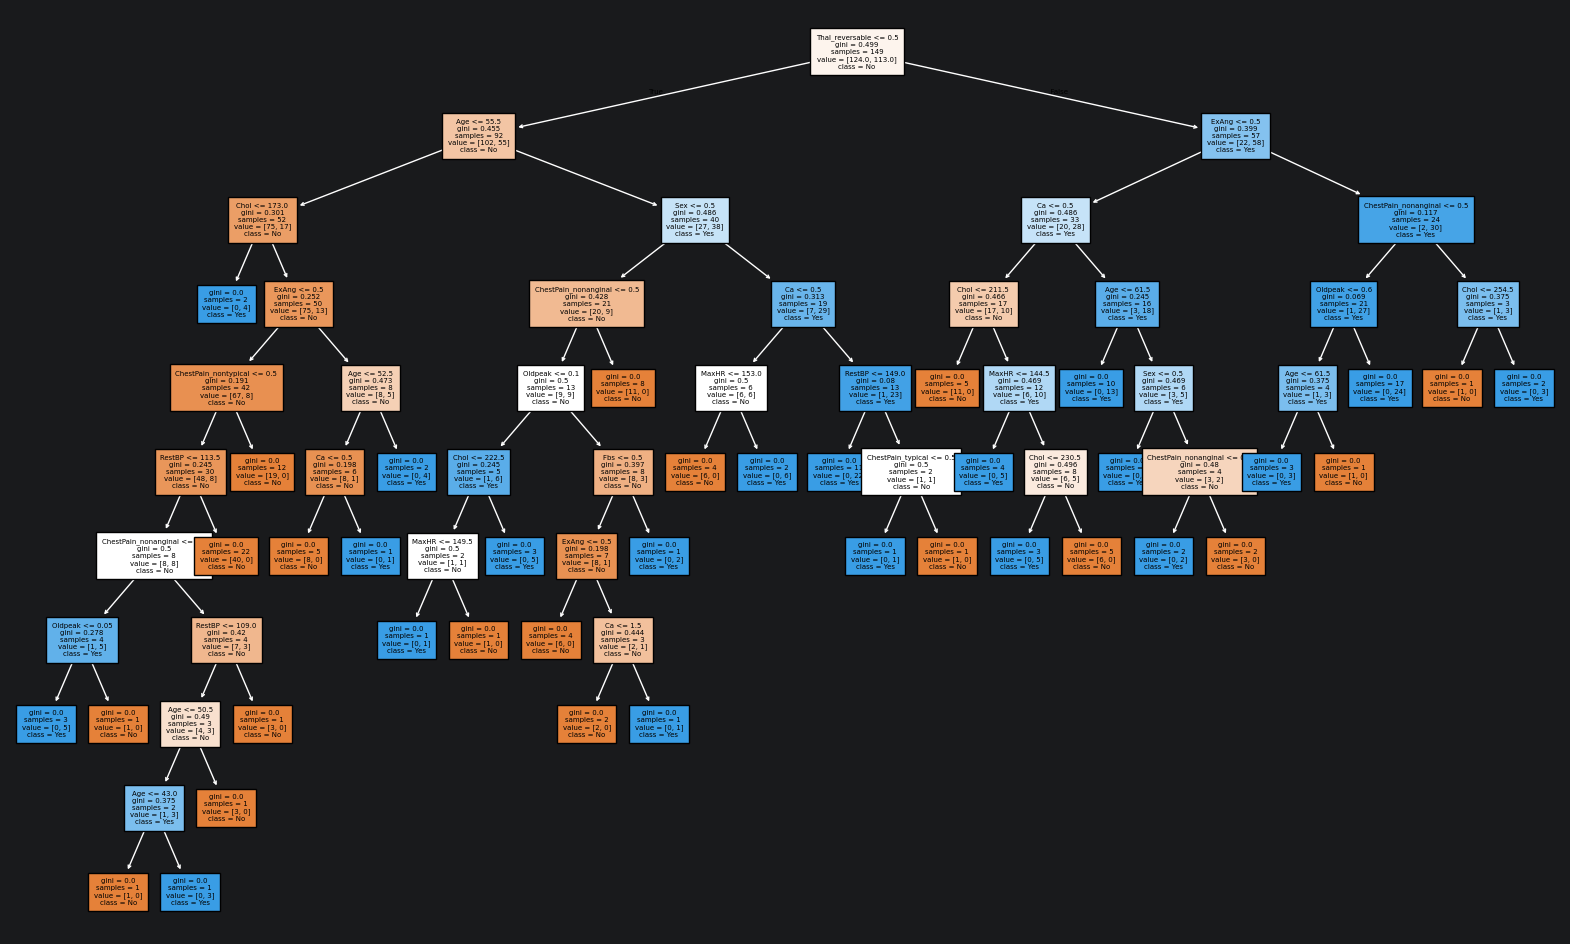

In [6]:
rf = RandomForestClassifier(n_estimators = 200, random_state = 40)
rf.fit(X_train, y_train)

# Plotting
fig, ax = plt.subplots(figsize=(20, 12))

plot_tree(
    rf.estimators_[0],
    feature_names=X.columns,
    class_names=[str(c) for c in rf.classes_],
    filled=True,
    fontsize=5,
    ax=ax
)

for text in ax.texts:
    text.set_color("black")

plt.show()

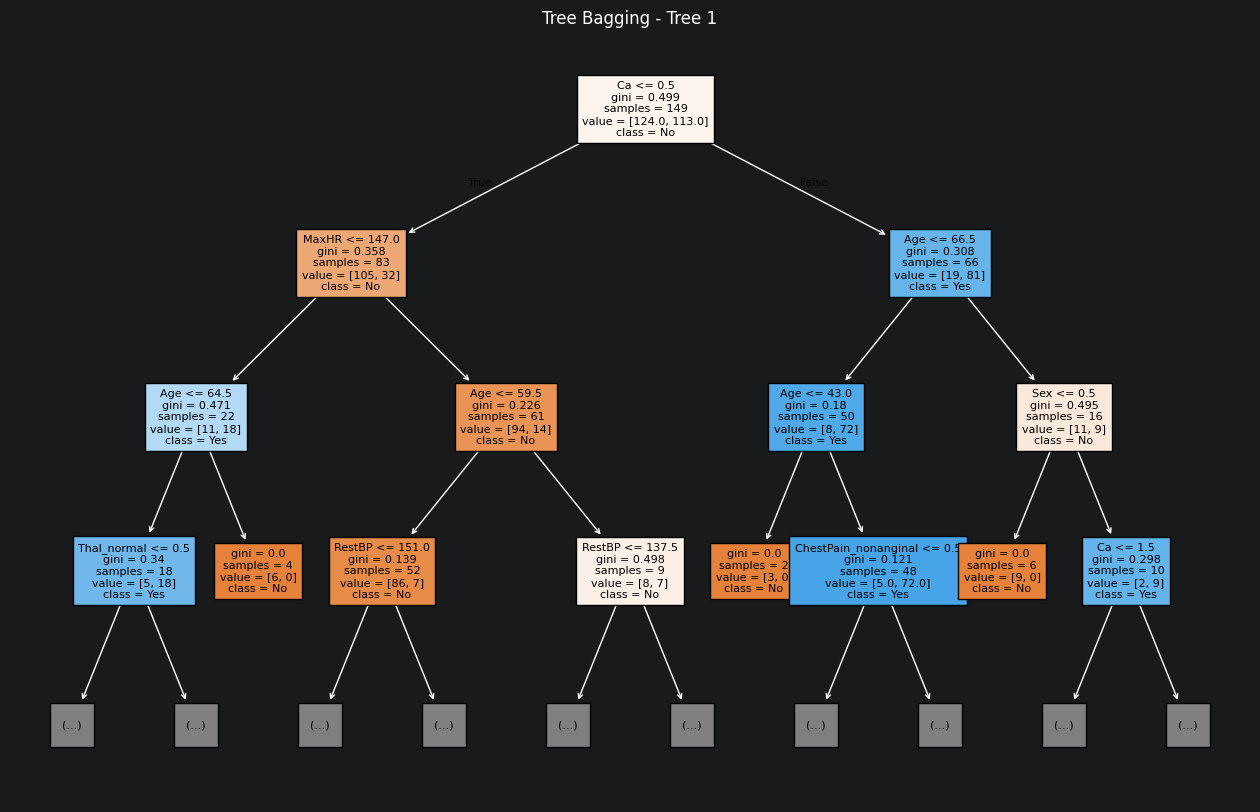

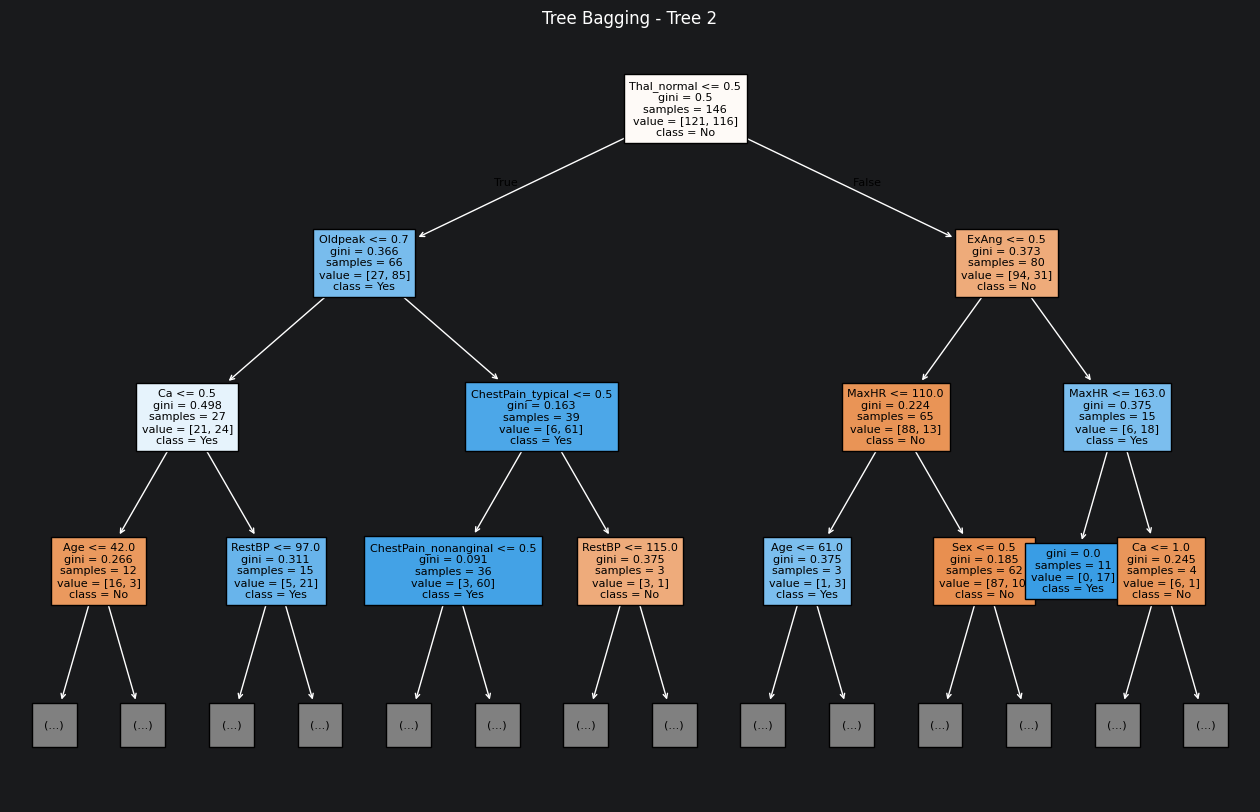

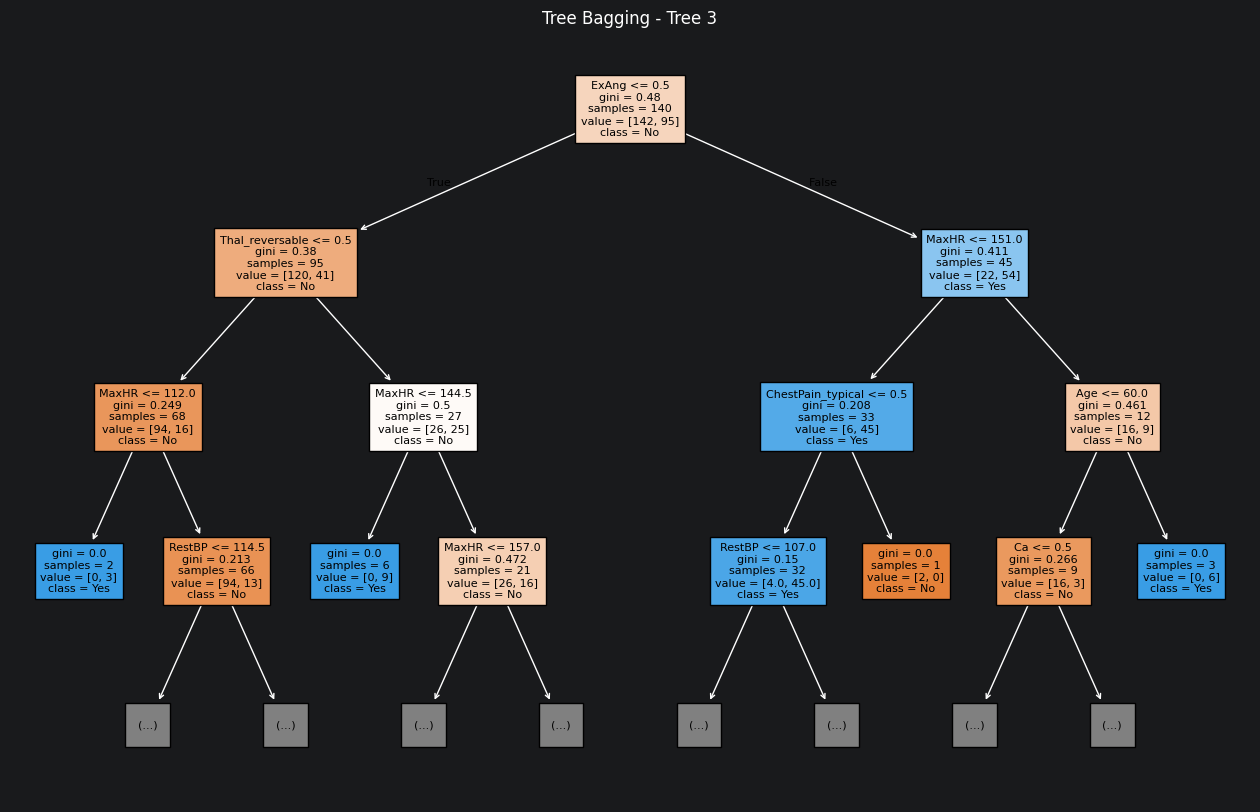

In [7]:
bagging = RandomForestClassifier(n_estimators = 200,max_features=None, random_state = 40)
bagging.fit(X_train, y_train)

# Plotting (3 trees)
for i in range(3):
    fig, ax = plt.subplots(figsize=(16, 10))

    plot_tree(
        bagging.estimators_[i],
        feature_names=X.columns,
        class_names=[str(c) for c in bagging.classes_],
        filled=True,
        max_depth=3,
        fontsize=8,
        ax=ax
    )

    for text in ax.texts:
        text.set_color("black")

    plt.title(f"Tree Bagging - Tree {i+1}")
    plt.show()

### 1.2 Tune the Forest

Now tune the hyper-parameters "max_features" and "min_samples_leaf" of the Random Forest classifier to minimize the expected generalization error.

You could use cross-validation. Is there another way to get the desired estimate other than with cross-validation? Use 2000 trees per forest or more.

_Hint:_ `sklearn.model_selection.ParameterGrid` and `<RF_instance>.set_params(...)` might be useful.

_Tip:_ In sklearn, you can set `n_jobs=-1` (or `n_jobs=-2`) in some models and in grid searches to use all (or all but one) of your computer's cores in parallel, which can reduce the running time depending on your computer. Be careful not to "nest" the parallelization.

In [8]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    'max_features': ['sqrt', 'log2', None],
    'min_samples_leaf': [1, 2, 5, 10]
}

grid = ParameterGrid(param_grid)

print(f"Number of combinations: {len(grid)}")

print(list(grid))


Number of combinations: 12
[{'max_features': 'sqrt', 'min_samples_leaf': 1}, {'max_features': 'sqrt', 'min_samples_leaf': 2}, {'max_features': 'sqrt', 'min_samples_leaf': 5}, {'max_features': 'sqrt', 'min_samples_leaf': 10}, {'max_features': 'log2', 'min_samples_leaf': 1}, {'max_features': 'log2', 'min_samples_leaf': 2}, {'max_features': 'log2', 'min_samples_leaf': 5}, {'max_features': 'log2', 'min_samples_leaf': 10}, {'max_features': None, 'min_samples_leaf': 1}, {'max_features': None, 'min_samples_leaf': 2}, {'max_features': None, 'min_samples_leaf': 5}, {'max_features': None, 'min_samples_leaf': 10}]


In [9]:
rf = RandomForestClassifier(
    n_estimators=2000,
    oob_score=True,
    n_jobs=-1,
    random_state=40
)

results = []

for params in grid:

    rf.set_params(**params)

    rf.fit(X_train, y_train)

    oob_error = 1 - rf.oob_score_

    results.append({
        'max_features': params['max_features'],
        'min_samples_leaf': params['min_samples_leaf'],
        'OOB Error': oob_error
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='OOB Error'
).reset_index(drop=True)

print(results_df)

   max_features  min_samples_leaf  OOB Error
0          None                 5   0.160338
1          sqrt                 5   0.168776
2          log2                 5   0.168776
3          None                 2   0.177215
4          None                10   0.177215
5          sqrt                 2   0.181435
6          log2                 2   0.181435
7          sqrt                 1   0.185654
8          sqrt                10   0.185654
9          log2                 1   0.185654
10         log2                10   0.185654
11         None                 1   0.189873


In [10]:
best_params = results_df.iloc[0]

print("Best hyperparameters:")
print(best_params)

Best hyperparameters:
max_features            None
min_samples_leaf           5
OOB Error           0.160338
Name: 0, dtype: object


In [11]:
best_rf = RandomForestClassifier(
    n_estimators=2000,
    max_features=best_params['max_features'],
    min_samples_leaf=int(best_params['min_samples_leaf']),
    oob_score=True,
    n_jobs=-1,
    random_state=40
)

best_rf.fit(X_train, y_train)

print("Best OOB accuracy:", best_rf.oob_score_)
print("Best OOB error:", 1 - best_rf.oob_score_)

Best OOB accuracy: 0.8396624472573839
Best OOB error: 0.16033755274261607


In [12]:
from sklearn.metrics import accuracy_score

y_pred = best_rf.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_error = 1 - test_accuracy

print("OOB error:", 1 - best_rf.oob_score_)
print("Test error:", test_error)

OOB error: 0.16033755274261607
Test error: 0.19999999999999996


_Remark:_ When comparing the Random Forest performance with other models, it is better to use cross-validation error estimates, so that the estimates are comparable between models.

### 2.3. Model Diagnostic

We now want to use different metrics to evaluate the model performance on the test set. To do so, consider the best random forest model according to cross-validation score. The first step is to predict the response classes on the test set.

In [13]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid:
param_grid = {
    'max_features': ['sqrt', 'log2', None],
    'min_samples_leaf': [1, 2, 5, 10]
}

# Create the Random Forest:
rf = RandomForestClassifier(
    n_estimators=2000,
    random_state=40,
    n_jobs=1
)

# Apply GridSearchCV:
grid_search_cv = GridSearchCV(
    estimator = rf,
    param_grid= param_grid,
    scoring = 'accuracy',
    n_jobs=-1,
    cv=5
)

grid_search_cv.fit(X_train, y_train)

#Retrieve the best model
best_rf_cv = grid_search_cv.best_estimator_
print("Best hyperparameters:", grid_search_cv.best_params_)
print("Best CV accuracy:", grid_search_cv.best_score_)




Best hyperparameters: {'max_features': 'sqrt', 'min_samples_leaf': 5}
Best CV accuracy: 0.8397163120567376


In [14]:
# Predict the response classes on the test set
y_pred_cv = best_rf_cv.predict(X_test)

print(y_pred_cv)

# Calculate test accuracy and error
test_accuracy_cv = accuracy_score(y_test, y_pred_cv)
test_error_cv = 1 - test_accuracy_cv

print("CV error:", 1 - grid_search_cv.best_score_)
print("Test error:", test_error_cv)

['No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'No'
 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No'
 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'No' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No'
 'No' 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'No']
CV error: 0.16028368794326242
Test error: 0.16666666666666663


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

Compute the confusion matrix using the `confusion_matrix()` function and plot it. You can use the `ConfusionMatrixDisplay` helper, or create the plot yourself. Comment the results.

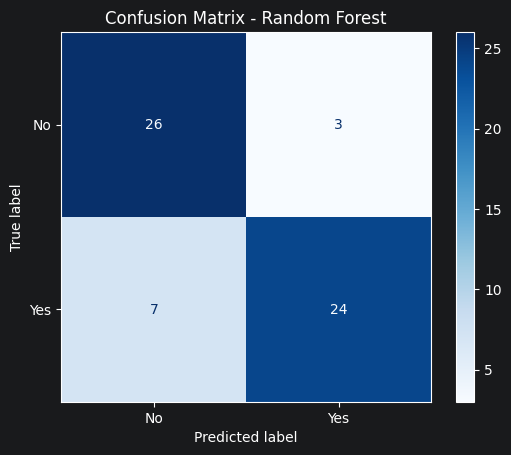

In [16]:

cm = confusion_matrix(
    y_test,
    y_pred_cv,
    labels=['No', 'Yes']
)

#  Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')

plt.title("Confusion Matrix - Random Forest")
plt.show()

Perform a classification report using the `classification_report()` function, and comment the results.

In [17]:
print(classification_report(
    y_test,
    y_pred_cv,
    target_names=['No', 'Yes']
))

              precision    recall  f1-score   support

          No       0.79      0.90      0.84        29
         Yes       0.89      0.77      0.83        31

    accuracy                           0.83        60
   macro avg       0.84      0.84      0.83        60
weighted avg       0.84      0.83      0.83        60



Plot the [Receiver Operating Characteristic (ROC)](https://en.wikipedia.org/wiki/Receiver_operating_characteristic) and estimate its Area Under Curve (AUC) using `roc_curve` and `roc_auc_score`. See e.g. `RocCurveDisplay` or `RocCurveDisplay.from_estimator` for plot helpers. Comment the results.

In [18]:
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay
print(best_rf_cv.classes_)

['No' 'Yes']


AUC: 0.9321468298109009


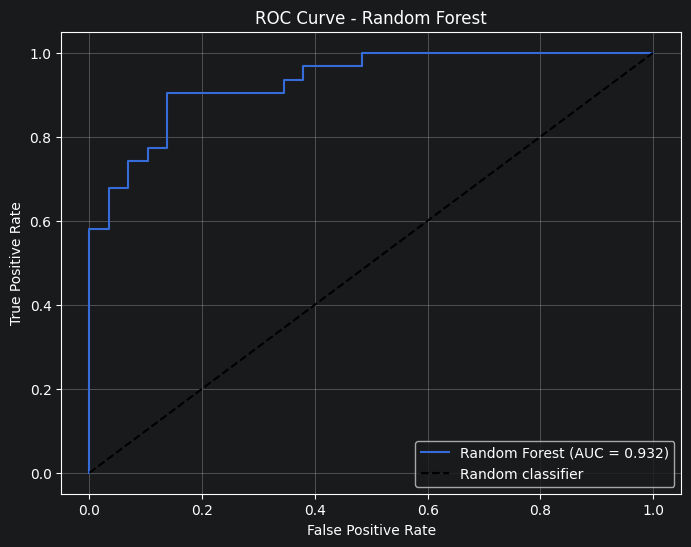

In [19]:


# Get the probability of AHD = Yes
yes_index = list(best_rf_cv.classes_).index('Yes')
y_proba_cv = best_rf_cv.predict_proba(X_test)[:, yes_index]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba_cv,
    pos_label='Yes'
)

# Calculate AUC
auc_cv = roc_auc_score(
    y_test == 'Yes',
    y_proba_cv
)

print("AUC:", auc_cv)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest (AUC = {auc_cv:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.grid()
plt.show()

One can also have a look at the `yellowbrick` package for more pre-coded diagnostic plots (with `pip install yellowbrick` (https://www.scikit-yb.org/en/latest/)).

## 3. Theoretical Exercise: Properties of Bootstrap

We will now derive the probability that a given observation is part
of a bootstrap sample. 

Let $Z = \{Z_1, \dots, Z_n\}$ be our original sample of size $n$. (For example, $Z_i = (X_i, Y_i)$
can represent the pair of predictors and target variables for each observation $i = 1, \dots, n$.)

Let $Z^* = \{Z_1^*, \dots, Z_n^*\}$ be a bootstrap sample of size $n$, resampled from $Z$. (You can think of it as one of the $B$ bootstrap samples $Z^{*1},\ldots,Z^{*B}$ used for bagging.)

We want to show that, for each $i = 1, \dots, n$, the probability that $Z_i$ is part of the bootstrap sample is $P\left(Z_i \in Z^*\right) = 1 - 1/e$.

* What is the probability that the first bootstrap observation
is not the $i$-th observation from the original sample? 
Justify your answer.

* What is the probability that the second bootstrap observation
is not the $i$-th observation from the original sample?

* Argue that the probability that the $i$-th observation is not in the
bootstrap sample is $(1 - \frac{1}{n})^n$.

* When $n = 5$, what is the probability that the $i$-th observation is
in the bootstrap sample?

* When $n = 100$, what is the probability that the $i$-th observation
is in the bootstrap sample?

* When $n \to \infty$, what is the probability that the $i$-th observation
is in the bootstrap sample?